# Regresión de potencia eléctrica: evaluación reservada

Consulta la [metodología](../docs/metodologia.md) y ejecuta las etapas en orden. Los comentarios se calculan con los resultados guardados.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("power_plant_regression")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre este notebook desde su proyecto independiente.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from power_plant_regression.alerts import configurar_notebook, mostrar_alertas
from IPython.display import display, Markdown, Image
configurar_notebook()


# Regresión de potencia eléctrica: evaluacion

En **1906 casos de test**, MAE **2.471 MW**, frente a **14.806 MW**: **mejora** el baseline. R² **0.9629**. Cobertura empírica **88.35%**, nominal **90%**, con ancho **9.884 MW**. Se reporta la cobertura observada sin reajustar el intervalo con test. Diagnóstico de residuos: correlación entre residuo absoluto y predicción **0.035** (sin señal clara de heterocedasticidad); sesgo (skewness) **-0.228**. La galería representa las 80 predicciones menores, no una muestra aleatoria. No se demuestra generalización a plantas distintas, otros regímenes ni futuros periodos.


,Indicador,Valor
0,modelo_elegido,HGB_hojas_31
1,cobertura_nominal,0.9
2,cobertura_empirica_test,0.883526
3,ancho_medio_intervalo_mw,9.884308
4,residuos_corr_pred_abs,0.035441
5,residuos_sesgo,-0.227706


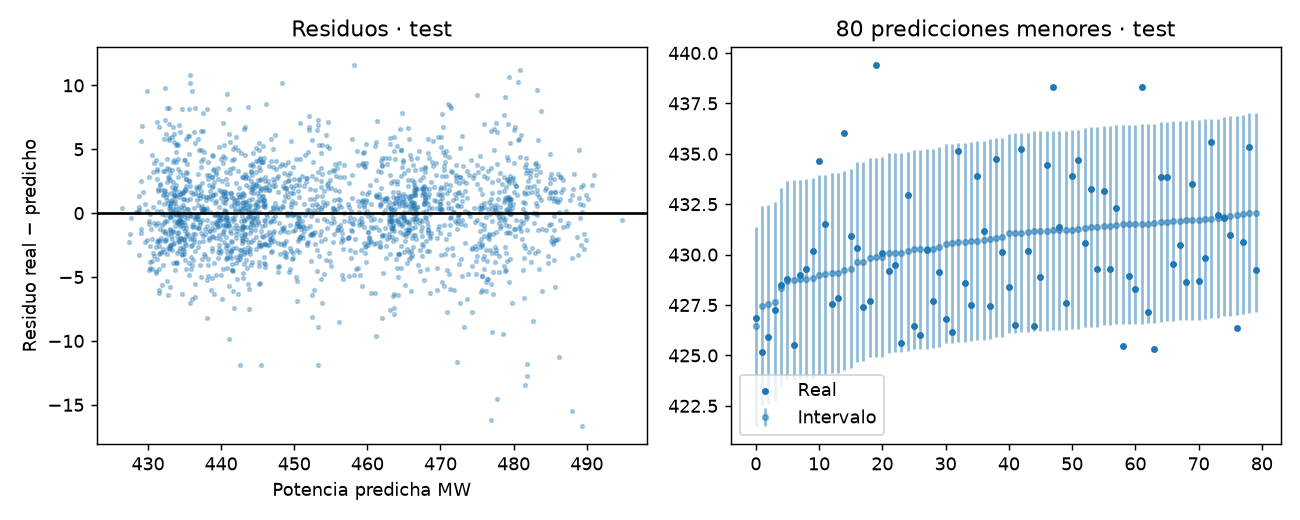

,estimador,casos,mae_mw,rmse_mw,r2
0,baseline,1906,14.805806,17.062481,-0.003013
1,modelo,1906,2.470522,3.282124,0.962886


In [2]:
from power_plant_regression.analysis import run_stage
import pandas as pd
metrics,comment=run_stage(PROJECT_ROOT,"evaluacion")
display(Markdown(comment))
scalars={k:v for k,v in metrics.items() if not isinstance(v,(dict,list))}
if scalars:display(pd.DataFrame(list(scalars.items()),columns=["Indicador","Valor"]))
if "candidatos" in metrics:display(pd.DataFrame(metrics["candidatos"]))
for filename in ["eda.png","evaluacion.png"]:
    path=PROJECT_ROOT/"reports/evaluacion"/filename
    if path.exists():display(Image(filename=str(path)))
for filename in ["estimaciones.csv","metricas_test.csv","horas_por_empleado.csv"]:
    path=PROJECT_ROOT/"reports/evaluacion"/filename
    if path.exists():display(pd.read_csv(path).head(20))

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from power_plant_regression.informe import generar_informe
generar_informe(PROJECT_ROOT)
display(Markdown("[Abrir informe integral](../reports/informe_final/informe_final.md)"))

[Abrir informe integral](../reports/informe_final/informe_final.md)